# 10 · Modelo en cascada — Churn general → Baja2 específico

## Arquitectura

```
Modelo 1 (detector general)
  target:  es_baja = 1 si baja1 o baja2, 0 si continua
  output:  prob_baja  → se agrega como feature al Modelo 2

Modelo 2 (refinador baja2)
  target:  es_baja2 = 1 si baja2, 0 si continua  (baja1 excluido)
  input:   features originales + prob_baja del Modelo 1
  output:  prob_baja2 → threshold → ganancia
```

## Optuna

Optimiza ambos modelos juntos con **parámetros compartidos** para la arquitectura
del árbol y **parámetros separados** solo para el manejo del desbalance
(el ratio neg/pos es distinto en cada modelo).

- `boosting_type`: gbdt o goss (sin DART para mantener tiempos razonables)
- GOSS: incompatible con bagging → bagging_fraction=1.0, bagging_freq=0
- 20 trials — warm start desde params del v5

**Submission:** `submissions6/`  
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Deadline:** 11/10/2026 23:59:59

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna lightgbm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.7 MB/s eta 0:00:00


In [3]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions6'
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B           = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_V5          = RUTA_COMP / 'mejores_params_optuna_v5.json'
CKPT_V10         = RUTA_COMP / 'mejores_params_optuna_v10.json'
CKPT_PROBS       = RUTA_COMP / 'probs_semillerio_v10.npy'
CKPT_IDS         = RUTA_COMP / 'ids_pred_v10.npy'
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET_M1   = 'es_baja'    # baja1 + baja2
TARGET_M2   = 'es_baja2'   # solo baja2

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108
GANANCIA_TP      =  1_072_500
COSTO_FP         =    -27_500
SEED             = 42
N_TRIALS         = 20

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_V5, CKPT_V10]:
    print(f'  {ck.name}: {"✓" if ck.exists() else "✗"}')
print(f'Submissions en: {RUTA_SUBS}')

Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v5.json: ✓
  mejores_params_optuna_v10.json: ✗
Submissions en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions6


## 1 · Funciones base

In [4]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp   = ((y_true == 1) & (pred == 1)).sum()
        fp   = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia':  tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def evaluar_fold(y_true, y_prob, label=''):
    auc = roc_auc_score(y_true, y_prob)
    opt = threshold_optimo(y_true, y_prob)
    print(f'  [{label}] AUC={auc:.4f} | Ganancia=${opt["ganancia"]:,.0f} | '
          f'N={opt["n_intervenidos"]:,} | TP={opt["tp"]} | FP={opt["fp"]} | '
          f'thresh={opt["threshold"]:.4f}')
    return {'auc': round(auc, 4), **opt}

print('✓ Funciones listas.')

✓ Funciones listas.


## 2 · Carga de datos y construcción de targets

In [5]:
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'Dataset: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

# ── Target Modelo 1: es_baja = baja1 OR baja2 ─────────────────────────────
# continua → 0, baja1 → 1, baja2 → 1, sin_target → NaN
df[TARGET_M1] = np.where(
    df[TARGET_RAW] == 'continua',  0,
    np.where(
        df[TARGET_RAW].isin(['baja1', 'baja2']), 1,
        np.nan  # meses sin target
    )
)

# ── Target Modelo 2: es_baja2 (ya existe en el parquet) ───────────────────
# continua → 0, baja2 → 1, baja1 → NaN, sin_target → NaN
# Verificamos que exista
assert TARGET_M2 in df.columns, f'{TARGET_M2} no encontrado en el parquet'

# ── Feature cols (excluir ambos targets y columnas de ID) ─────────────────
EXCLUIR      = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET_M1, TARGET_M2}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# ── Ratios de desbalance ───────────────────────────────────────────────────
mask_e = df[COL_PERIODO].isin(MESES_CON_TARGET)

# Modelo 1: baja1+baja2 vs continua (baja1 NO es NaN aquí)
y_m1_ref      = df.loc[mask_e & df[TARGET_M1].notna(), TARGET_M1]
SCALE_M1      = float((y_m1_ref == 0).sum() / (y_m1_ref == 1).sum())

# Modelo 2: solo baja2 vs continua (baja1 sí es NaN aquí)
y_m2_ref      = df.loc[mask_e & df[TARGET_M2].notna(), TARGET_M2]
SCALE_M2      = float((y_m2_ref == 0).sum() / (y_m2_ref == 1).sum())

del y_m1_ref, y_m2_ref; gc.collect()

print(f'\nDesbalance Modelo 1 (baja general): {SCALE_M1:.1f}:1')
print(f'Desbalance Modelo 2 (baja2 solo):   {SCALE_M2:.1f}:1')
print(f'Features: {len(FEATURE_COLS):,}')

# Verificar distribución de targets
for mes in MESES_CON_TARGET:
    mask_m = df[COL_PERIODO] == mes
    n_baja1  = (df.loc[mask_m, TARGET_RAW] == 'baja1').sum()
    n_baja2  = (df.loc[mask_m, TARGET_RAW] == 'baja2').sum()
    n_cont   = (df.loc[mask_m, TARGET_RAW] == 'continua').sum()
    print(f'  {mes}: continua={n_cont:,} | baja1={n_baja1:,} | baja2={n_baja2:,}')

Dataset: 983,061 × 327 — 1041.6 MB

Desbalance Modelo 1 (baja general): 80.1:1
Desbalance Modelo 2 (baja2 solo):   158.8:1
Features: 323
  202103: continua=160,921 | baja1=1,019 | baja2=960
  202104: continua=161,181 | baja1=964 | baja2=1,139
  202105: continua=161,755 | baja1=1,143 | baja2=870
  202106: continua=162,142 | baja1=874 | baja2=1,098


In [6]:
# Params del v5 como punto de partida para warm start
with open(CKPT_V5) as f:
    p_v5 = json.load(f)

# Extraemos solo los params estructurales (sin desbalance, sin meta)
KEYS_STRUCT = {'num_leaves', 'max_depth', 'learning_rate', 'n_estimators',
               'min_child_samples', 'feature_fraction', 'bagging_fraction',
               'bagging_freq', 'reg_alpha', 'reg_lambda', 'min_split_gain'}
WARM_STRUCT = {k: v for k, v in p_v5.items() if k in KEYS_STRUCT}

N_MESES_V5 = p_v5.get('n_meses_train', 3)
print(f'Params v5 cargados | ventana: {N_MESES_V5} meses')
print(f'Ganancia v5 fold_4: ${p_v5["ganancia_optuna_fold4"]:,.0f}')

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_meses_train(fold_nombre, n_ventana):
    fold_map = {
        'fold_2': [202103],
        'fold_3': [202103, 202104],
        'fold_4': [202103, 202104, 202105],
    }
    return fold_map[fold_nombre][-n_ventana:]

def get_split_m1(meses_train, mes_test):
    """Split para Modelo 1 — target es_baja (baja1+baja2 vs continua).""",
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET_M1].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[TARGET_M1].notna()
    return (df.loc[mt, FEATURE_COLS].copy(),
            df.loc[mt, TARGET_M1].astype(int).copy(),
            df.loc[me, FEATURE_COLS].copy(),
            df.loc[me, TARGET_M1].astype(int).copy())

def get_split_m2(meses_train, mes_test, col_prob_m1='prob_baja_m1'):
    """Split para Modelo 2 — target es_baja2 (baja2 vs continua, baja1 excluido).
    Incluye prob_baja_m1 si está disponible en df.""",
    feats = FEATURE_COLS + ([col_prob_m1] if col_prob_m1 in df.columns else [])
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET_M2].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[TARGET_M2].notna()
    return (df.loc[mt, feats].copy(),
            df.loc[mt, TARGET_M2].astype(int).copy(),
            df.loc[me, feats].copy(),
            df.loc[me, TARGET_M2].astype(int).copy())

Params v5 cargados | ventana: 3 meses
Ganancia v5 fold_4: $430,980,000


---
## 3 · Optuna — optimización conjunta de ambos modelos

**Espacio de búsqueda:**
- Parámetros de árbol: **compartidos** entre M1 y M2
- `scale_pos_weight`: **separado** para cada modelo (desbalance distinto)
- `boosting_type`: gbdt o goss (sin DART para tiempos razonables)
- GOSS: bagging desactivado automáticamente

**Evaluación:** ganancia en fold_4 con el threshold óptimo — solo baja2 cuenta como TP.

Si `CKPT_V10` existe, carga directo y salta al walk-forward.

In [7]:
if CKPT_V10.exists():
    print('✓ CKPT_V10 encontrado — cargando...')
    with open(CKPT_V10) as f:
        p_v10 = json.load(f)
    print(f'  Ganancia fold_4: ${p_v10["ganancia_fold4"]:,.0f}')
    print(f'  boosting:        {p_v10["boosting_type"]}')
    print(f'  spw_m1:          {p_v10["scale_pos_weight_m1"]:.2f}')
    print(f'  spw_m2:          {p_v10["scale_pos_weight_m2"]:.2f}')
    print('  → Saltá a la sección 4.')
else:
    print('✗ CKPT_V10 no encontrado — ejecutar Optuna.')

✗ CKPT_V10 no encontrado — ejecutar Optuna.


In [8]:
if not CKPT_V10.exists():

    # Pre-computamos el split de fold_4 para el objetivo
    # M1 necesita todos los casos (incluyendo baja1)
    # M2 excluye baja1 — pero prob_m1 se agrega dinámicamente dentro del objetivo
    meses_tr_opt = get_meses_train('fold_4', N_MESES_V5)
    mes_test_opt = 202106

    Xtr_m1_opt, ytr_m1_opt, Xte_m1_opt, yte_m1_opt = get_split_m1(
        meses_tr_opt, mes_test_opt)

    # Para M2 lo construimos sin prob_m1 todavía (se agrega dentro del objective)
    mt_m2 = df[COL_PERIODO].isin(meses_tr_opt) & df[TARGET_M2].notna()
    me_m2 = (df[COL_PERIODO] == mes_test_opt)   & df[TARGET_M2].notna()
    Xtr_m2_base = df.loc[mt_m2, FEATURE_COLS].copy()
    ytr_m2_opt  = df.loc[mt_m2, TARGET_M2].astype(int).copy()
    Xte_m2_base = df.loc[me_m2, FEATURE_COLS].copy()
    yte_m2_opt  = df.loc[me_m2, TARGET_M2].astype(int).copy()
    yte_m2_arr  = yte_m2_opt.values

    # Índice de test M2 dentro de test M1 (para extraer prob_m1 correctamente)
    # me_m2 filtra baja1 de me_m1, así que necesitamos alinear por índice
    idx_te_m2_en_m1 = df.index[me_m2]

    print(f'fold_4 M1 train: {len(ytr_m1_opt):,} | test: {len(yte_m1_opt):,}')
    print(f'fold_4 M2 train: {len(ytr_m2_opt):,} | test: {len(yte_m2_opt):,}')

    def objective_cascada(trial):

        # ── Parámetros compartidos ─────────────────────────────────────────
        boosting   = trial.suggest_categorical('boosting_type', ['gbdt', 'goss'])
        num_leaves = trial.suggest_int('num_leaves', 16, 256)
        max_depth  = trial.suggest_int('max_depth', 4, 12)
        lr         = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)
        n_est      = trial.suggest_int('n_estimators', 100, 800, step=50)
        min_child  = trial.suggest_int('min_child_samples', 20, 2000, log=True)
        feat_frac  = trial.suggest_float('feature_fraction', 0.4, 1.0)
        min_split  = trial.suggest_float('min_split_gain', 0.0, 1.0)
        reg_a      = trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True)
        reg_l      = trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True)

        # GOSS incompatible con bagging
        if boosting == 'goss':
            bag_frac = 1.0
            bag_freq = 0
        else:
            bag_frac = trial.suggest_float('bagging_fraction', 0.4, 1.0)
            bag_freq = trial.suggest_int('bagging_freq', 1, 7)

        # ── Scale pos weight separado por modelo ───────────────────────────
        spw_m1 = trial.suggest_float('scale_pos_weight_m1',
                                     SCALE_M1 / 4, SCALE_M1 * 3)
        spw_m2 = trial.suggest_float('scale_pos_weight_m2',
                                     SCALE_M2 / 4, SCALE_M2 * 5)

        params_shared = {
            'objective':         'binary',
            'metric':            'binary_logloss',
            'boosting_type':     boosting,
            'verbosity':         -1,
            'n_jobs':            -1,
            'random_state':      SEED,
            'num_leaves':        num_leaves,
            'max_depth':         max_depth,
            'learning_rate':     lr,
            'n_estimators':      n_est,
            'min_child_samples': min_child,
            'feature_fraction':  feat_frac,
            'bagging_fraction':  bag_frac,
            'bagging_freq':      bag_freq,
            'reg_alpha':         reg_a,
            'reg_lambda':        reg_l,
            'min_split_gain':    min_split,
        }

        # ── Modelo 1: detector general ────────────────────────────────────
        params_m1 = {**params_shared, 'scale_pos_weight': spw_m1}
        m1 = lgb.LGBMClassifier(**params_m1)
        m1.fit(Xtr_m1_opt, ytr_m1_opt,
               eval_set=[(Xte_m1_opt, yte_m1_opt)],
               callbacks=[lgb.early_stopping(30, verbose=False),
                          lgb.log_evaluation(-1)])

        # Probabilidades M1 sobre train y test de M2
        # Train M2: necesitamos prob_m1 del train — usamos out-of-fold para no leakear
        # Simplificación válida para Optuna: usamos prob directa del train
        # (en el walk-forward final usamos OOF correctamente)
        prob_m1_train = m1.predict_proba(Xtr_m2_base)[:, 1]
        prob_m1_test  = m1.predict_proba(Xte_m2_base)[:, 1]
        del m1; gc.collect()

        # ── Modelo 2: refinador baja2 ─────────────────────────────────────
        Xtr_m2_aug = Xtr_m2_base.copy()
        Xte_m2_aug = Xte_m2_base.copy()
        Xtr_m2_aug['prob_baja_m1'] = prob_m1_train
        Xte_m2_aug['prob_baja_m1'] = prob_m1_test

        params_m2 = {**params_shared, 'scale_pos_weight': spw_m2}
        m2 = lgb.LGBMClassifier(**params_m2)
        m2.fit(Xtr_m2_aug, ytr_m2_opt,
               eval_set=[(Xte_m2_aug, yte_m2_opt)],
               callbacks=[lgb.early_stopping(30, verbose=False),
                          lgb.log_evaluation(-1)])

        prob_final = m2.predict_proba(Xte_m2_aug)[:, 1]
        ganancia   = threshold_optimo(yte_m2_arr, prob_final)['ganancia']
        del m2, Xtr_m2_aug, Xte_m2_aug; gc.collect()
        return ganancia

    # ── Crear study con warm start ─────────────────────────────────────────
    if 'study_v10' not in globals():
        study_v10 = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=SEED),
            study_name='cascada_churn_v10'
        )
        warm = {**WARM_STRUCT,
                'boosting_type':       p_v5.get('boosting_type', 'gbdt')
                                       if p_v5.get('boosting_type') != 'dart' else 'gbdt',
                'scale_pos_weight_m1': SCALE_M1 * 2,
                'scale_pos_weight_m2': SCALE_M2 * 2,
                'min_split_gain':      WARM_STRUCT.get('min_split_gain', 0.0)}
        # GOSS no usa bagging — limpiar si corresponde
        if warm['boosting_type'] == 'goss':
            warm.pop('bagging_fraction', None)
            warm.pop('bagging_freq', None)
        study_v10.enqueue_trial(warm)
        print('Study v10 creado con warm start desde v5.')
    else:
        trials_ok = len([t for t in study_v10.trials if t.value is not None])
        print(f'Study v10 existente — {trials_ok} trials completados, retomando...')

    trials_restantes = N_TRIALS - len([t for t in study_v10.trials if t.value is not None])
    print(f'Corriendo {trials_restantes} trials (total={N_TRIALS})...')
    study_v10.optimize(objective_cascada, n_trials=trials_restantes,
                       show_progress_bar=True)

    del Xtr_m1_opt, ytr_m1_opt, Xte_m1_opt, yte_m1_opt
    del Xtr_m2_base, ytr_m2_opt, Xte_m2_base, yte_m2_opt
    gc.collect()

    bp = study_v10.best_params
    print(f'\n✓ Optuna completado — {N_TRIALS} trials')
    print(f'Mejor ganancia fold_4: ${study_v10.best_value:,.0f}')
    for k, v in bp.items():
        print(f'  {k}: {v}')

    # Guardar checkpoint
    guardar = {
        **bp,
        'ganancia_fold4':    study_v10.best_value,
        'n_trials':          N_TRIALS,
        'experimento':       'v10_cascada',
        'fecha':             datetime.now().isoformat(),
    }
    with open(CKPT_V10, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'✓ CKPT_V10 guardado')

fold_4 M1 train: 489,952 | test: 164,114
fold_4 M2 train: 486,826 | test: 163,240
Study v10 creado con warm start desde v5.
Corriendo 20 trials (total=20)...


  0%|          | 0/20 [00:00<?, ?it/s]


✓ Optuna completado — 20 trials
Mejor ganancia fold_4: $336,297,500
  boosting_type: gbdt
  num_leaves: 175
  max_depth: 6
  learning_rate: 0.05864129169696527
  n_estimators: 500
  min_child_samples: 46
  feature_fraction: 0.9817507766587351
  min_split_gain: 0.7751328233611146
  reg_alpha: 2.854239907497756
  reg_lambda: 1.1309571585271483
  bagging_fraction: 0.7587399872866512
  bagging_freq: 7
  scale_pos_weight_m1: 39.5074298426744
  scale_pos_weight_m2: 187.57615746608076
✓ CKPT_V10 guardado


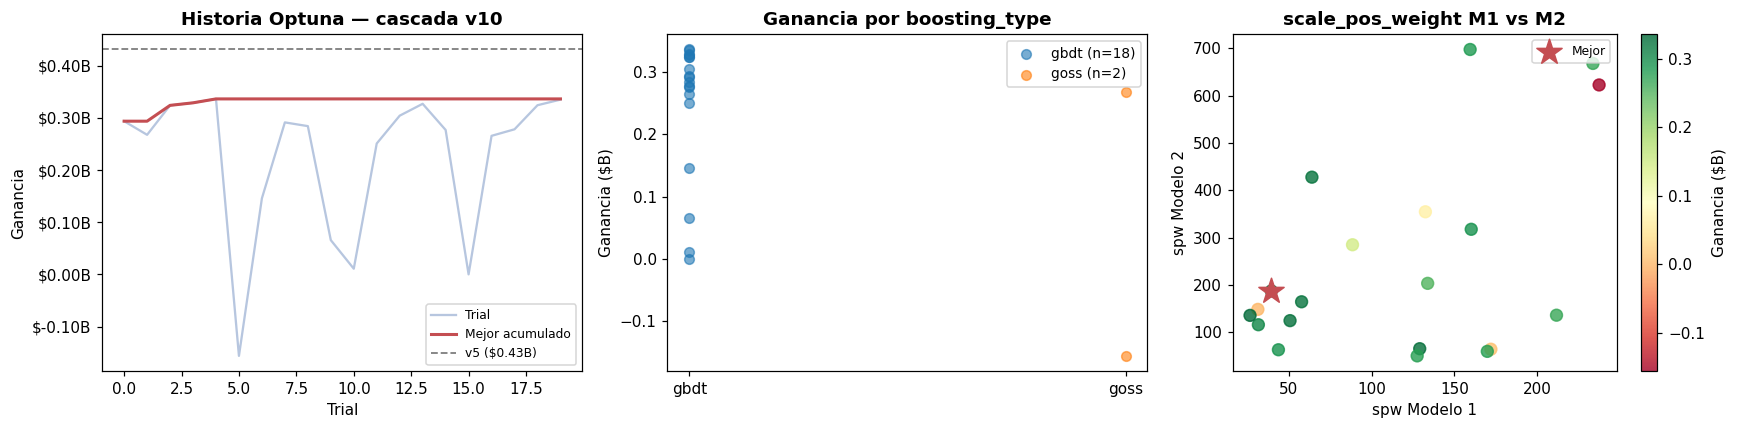

In [9]:
# Gráfico Optuna (solo si corrió en esta sesión)
if 'study_v10' in globals():
    valores   = [t.value for t in study_v10.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()
    g_v5_ref  = p_v5['ganancia_optuna_fold4']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(g_v5_ref, color='gray', ls='--', lw=1.2, label=f'v5 (${g_v5_ref/1e9:.2f}B)')
    ax.set_title('Historia Optuna — cascada v10', fontweight='bold')
    ax.set_xlabel('Trial'); ax.set_ylabel('Ganancia')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend(fontsize=8)

    ax = axes[1]
    for bt, color in [('gbdt', '#4C72B0'), ('goss', '#55A868')]:
        g_vals = [t.value/1e9 for t in study_v10.trials
                  if t.value is not None and t.params.get('boosting_type') == bt]
        if g_vals:
            ax.scatter([bt]*len(g_vals), g_vals, alpha=0.6, s=40,
                       label=f'{bt} (n={len(g_vals)})')
    ax.set_title('Ganancia por boosting_type', fontweight='bold')
    ax.set_ylabel('Ganancia ($B)'); ax.legend(fontsize=9)

    ax = axes[2]
    spw1 = [t.params.get('scale_pos_weight_m1', 0) for t in study_v10.trials
            if t.value is not None]
    spw2 = [t.params.get('scale_pos_weight_m2', 0) for t in study_v10.trials
            if t.value is not None]
    gans = [t.value/1e9 for t in study_v10.trials if t.value is not None]
    sc   = ax.scatter(spw1, spw2, c=gans, cmap='RdYlGn', s=60, alpha=0.8)
    plt.colorbar(sc, ax=ax, label='Ganancia ($B)')
    bp_v = study_v10.best_params
    ax.scatter([bp_v['scale_pos_weight_m1']], [bp_v['scale_pos_weight_m2']],
               marker='*', s=300, color='#C44E52', zorder=5, label='Mejor')
    ax.set_title('scale_pos_weight M1 vs M2', fontweight='bold')
    ax.set_xlabel('spw Modelo 1'); ax.set_ylabel('spw Modelo 2')
    ax.legend(fontsize=8)

    plt.tight_layout(); plt.show()
else:
    print('(Gráficos disponibles solo si Optuna corrió en esta sesión)')

---
## 4 · Reconstruir parámetros desde checkpoint

In [10]:
if 'p_v10' not in globals():
    with open(CKPT_V10) as f:
        p_v10 = json.load(f)

bp = {k: v for k, v in p_v10.items()
      if k not in {'ganancia_fold4', 'n_trials', 'fecha', 'experimento'}}

PARAMS_SHARED = {
    'objective':         'binary',
    'metric':            'binary_logloss',
    'boosting_type':     bp['boosting_type'],
    'verbosity':         -1,
    'n_jobs':            -1,
    'random_state':      SEED,
    'num_leaves':        bp['num_leaves'],
    'max_depth':         bp['max_depth'],
    'learning_rate':     bp['learning_rate'],
    'n_estimators':      bp['n_estimators'],
    'min_child_samples': bp['min_child_samples'],
    'feature_fraction':  bp['feature_fraction'],
    'bagging_fraction':  bp.get('bagging_fraction', 1.0),
    'bagging_freq':      bp.get('bagging_freq', 0),
    'reg_alpha':         bp['reg_alpha'],
    'reg_lambda':        bp['reg_lambda'],
    'min_split_gain':    bp['min_split_gain'],
}
PARAMS_M1 = {**PARAMS_SHARED, 'scale_pos_weight': bp['scale_pos_weight_m1']}
PARAMS_M2 = {**PARAMS_SHARED, 'scale_pos_weight': bp['scale_pos_weight_m2']}

print('Parámetros reconstruidos:')
print(f'  boosting:   {PARAMS_SHARED["boosting_type"]}')
print(f'  num_leaves: {PARAMS_SHARED["num_leaves"]}')
print(f'  lr:         {PARAMS_SHARED["learning_rate"]:.4f}')
print(f'  spw M1:     {bp["scale_pos_weight_m1"]:.2f} (desbalance M1: {SCALE_M1:.1f})')
print(f'  spw M2:     {bp["scale_pos_weight_m2"]:.2f} (desbalance M2: {SCALE_M2:.1f})')

Parámetros reconstruidos:
  boosting:   gbdt
  num_leaves: 175
  lr:         0.0586
  spw M1:     39.51 (desbalance M1: 80.1)
  spw M2:     187.58 (desbalance M2: 158.8)


---
## 5 · Walk-forward completo con OOF para prob_m1

En el walk-forward usamos **Out-Of-Fold (OOF)** para generar `prob_baja_m1` en el train
del Modelo 2. Esto evita que el Modelo 2 vea en train las probabilidades del Modelo 1
calculadas sobre los mismos datos — lo que sería un leakage interno.

**Cómo funciona el OOF aquí:**
- El train del fold tiene K meses. Entrenamos M1 con K-1 meses y predecimos el mes restante.
- Hacemos esto para cada mes del train rotando, y ensamblamos las probabilidades.
- Con esas probabilidades OOF, entrenamos M2.
- Para el test, M1 se entrena con todos los meses del train y predice el test.

In [11]:
def entrenar_cascada_fold(meses_train, mes_test, params_m1, params_m2,
                           n_meses_ventana, fold_nombre):
    """
    Entrena el modelo en cascada para un fold con OOF para prob_m1 en train.
    Retorna las métricas de ganancia y AUC sobre el test (solo baja2).
    """
    es_goss = params_m1.get('boosting_type') == 'goss'

    # ── Test: siempre M2 (baja2 vs continua) ──────────────────────────────
    me_m2   = (df[COL_PERIODO] == mes_test) & df[TARGET_M2].notna()
    Xte_m2  = df.loc[me_m2, FEATURE_COLS].copy()
    yte_m2  = df.loc[me_m2, TARGET_M2].astype(int).copy()

    # ── M1 entrenado en todos los meses de train → prob en test ───────────
    mt_m1_all = df[COL_PERIODO].isin(meses_train) & df[TARGET_M1].notna()
    Xtr_m1_all = df.loc[mt_m1_all, FEATURE_COLS]
    ytr_m1_all = df.loc[mt_m1_all, TARGET_M1].astype(int)

    m1_full = lgb.LGBMClassifier(**{**params_m1, 'random_state': SEED})
    m1_full.fit(Xtr_m1_all, ytr_m1_all, callbacks=[lgb.log_evaluation(-1)])
    prob_m1_test = m1_full.predict_proba(Xte_m2)[:, 1]
    del Xtr_m1_all, ytr_m1_all; gc.collect()

    # ── OOF: prob_m1 en el train de M2 ────────────────────────────────────
    mt_m2_all = df[COL_PERIODO].isin(meses_train) & df[TARGET_M2].notna()
    idx_m2    = df.index[mt_m2_all]
    prob_m1_oof = np.zeros(mt_m2_all.sum(), dtype=np.float32)

    if len(meses_train) == 1:
        # Solo 1 mes de train: no hay OOF posible — usamos prob directa (fold_2)
        Xtr_m2_s = df.loc[mt_m2_all, FEATURE_COLS]
        ytr_m2_s = df.loc[mt_m2_all, TARGET_M2].astype(int)
        prob_m1_oof = m1_full.predict_proba(Xtr_m2_s)[:, 1].astype(np.float32)
        del Xtr_m2_s, ytr_m2_s
    else:
        # Rotamos meses: entrenamos M1 sin mes_k, predecimos mes_k
        for mes_oof in meses_train:
            meses_resto  = [m for m in meses_train if m != mes_oof]
            mt_m1_oof    = df[COL_PERIODO].isin(meses_resto) & df[TARGET_M1].notna()
            mt_m2_oof    = (df[COL_PERIODO] == mes_oof)       & df[TARGET_M2].notna()

            Xtr_oof = df.loc[mt_m1_oof, FEATURE_COLS]
            ytr_oof = df.loc[mt_m1_oof, TARGET_M1].astype(int)
            Xte_oof = df.loc[mt_m2_oof, FEATURE_COLS]

            m1_oof = lgb.LGBMClassifier(**{**params_m1, 'random_state': SEED})
            m1_oof.fit(Xtr_oof, ytr_oof, callbacks=[lgb.log_evaluation(-1)])

            # Mapear predicciones al índice correcto dentro del array OOF
            mask_in_m2 = df.index[mt_m2_oof]
            pos_in_oof = np.where(np.isin(idx_m2, mask_in_m2))[0]
            prob_m1_oof[pos_in_oof] = m1_oof.predict_proba(Xte_oof)[:, 1]
            del Xtr_oof, ytr_oof, Xte_oof, m1_oof; gc.collect()

    del m1_full; gc.collect()

    # ── M2: train con prob_m1 OOF como feature ────────────────────────────
    Xtr_m2 = df.loc[mt_m2_all, FEATURE_COLS].copy()
    ytr_m2 = df.loc[mt_m2_all, TARGET_M2].astype(int).copy()
    Xtr_m2['prob_baja_m1'] = prob_m1_oof

    Xte_m2_aug = Xte_m2.copy()
    Xte_m2_aug['prob_baja_m1'] = prob_m1_test

    m2 = lgb.LGBMClassifier(**{**params_m2, 'random_state': SEED})
    m2.fit(Xtr_m2, ytr_m2,
           eval_set=[(Xte_m2_aug, yte_m2)],
           callbacks=[lgb.early_stopping(50, verbose=False),
                      lgb.log_evaluation(-1)])

    prob_final = m2.predict_proba(Xte_m2_aug)[:, 1]
    del m2, Xtr_m2, ytr_m2, Xte_m2, Xte_m2_aug; gc.collect()

    return prob_final, yte_m2.values

print('✓ Función entrenar_cascada_fold lista.')

✓ Función entrenar_cascada_fold lista.


In [12]:
resultados_wf = []
print('=== WALK-FORWARD — MODELO EN CASCADA v10 ===')

for fold in FOLDS:
    meses_tr = get_meses_train(fold['nombre'], N_MESES_V5)
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} | train={meses_tr} | test={fold['test']}")
    print('='*55)

    prob_final, yte_arr = entrenar_cascada_fold(
        meses_train=meses_tr,
        mes_test=fold['test'],
        params_m1=PARAMS_M1,
        params_m2=PARAMS_M2,
        n_meses_ventana=N_MESES_V5,
        fold_nombre=fold['nombre'],
    )

    auc = roc_auc_score(yte_arr, prob_final)
    opt = threshold_optimo(yte_arr, prob_final)
    print(f'  AUC: {auc:.4f} | Ganancia: ${opt["ganancia"]:,.0f} | '
          f'N: {opt["n_intervenidos"]:,} | thresh: {opt["threshold"]:.4f}')

    resultados_wf.append({
        'fold':          fold['nombre'],
        'mes_test':      fold['test'],
        'experimento':   'v10_cascada',
        'meses_train':   str(meses_tr),
        'auc':           round(auc, 4),
        'ganancia':      opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp':            opt['tp'],
        'fp':            opt['fp'],
        'n_intervenidos':opt['n_intervenidos'],
    })

df_wf = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD v10 (cascada)\n{'='*55}")
print(df_wf[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))

g_v10_f4 = df_wf[df_wf.fold=='fold_4']['ganancia'].values[0]
g_v5_f4  = p_v5['ganancia_optuna_fold4']
delta    = g_v10_f4 - g_v5_f4
signo    = '+' if delta >= 0 else ''
print(f'\n--- vs v5 (fold_4) ---')
print(f'  v5 (base):       ${g_v5_f4:,.0f}')
print(f'  v10 (cascada):   ${g_v10_f4:,.0f}  ({signo}${delta/1e6:.1f}M)')
print()
if g_v10_f4 > g_v5_f4:
    print('✓ Cascada MEJORA sobre v5 → seguir con submission')
else:
    print('✗ Cascada NO mejora sobre v5')
    print('  Revisá los resultados. Podés igual submittear seteando FORZAR_SUBMIT=True.')

=== WALK-FORWARD — MODELO EN CASCADA v10 ===

  FOLD_2 | train=[202103] | test=202104
  AUC: 0.6299 | Ganancia: $428,807,500 | N: 4,367.0 | thresh: 0.0010

  FOLD_3 | train=[202103, 202104] | test=202105
  AUC: 0.8494 | Ganancia: $240,102,500 | N: 6,709.0 | thresh: 0.5030

  FOLD_4 | train=[202103, 202104, 202105] | test=202106
  AUC: 0.8506 | Ganancia: $348,287,500 | N: 12,815.0 | thresh: 0.2470

RESUMEN WALK-FORWARD v10 (cascada)
  fold    auc    ganancia  threshold_opt  n_intervenidos
fold_2 0.6299 428807500.0          0.001          4367.0
fold_3 0.8494 240102500.0          0.503          6709.0
fold_4 0.8506 348287500.0          0.247         12815.0

--- vs v5 (fold_4) ---
  v5 (base):       $430,980,000
  v10 (cascada):   $348,287,500  ($-82.7M)

✗ Cascada NO mejora sobre v5
  Revisá los resultados. Podés igual submittear seteando FORZAR_SUBMIT=True.


In [13]:
# Guardar métricas
df_wf['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    pd.concat([hist, df_wf], ignore_index=True).to_csv(ARCHIVO_METRICAS, index=False)
else:
    df_wf.to_csv(ARCHIVO_METRICAS, index=False)
print('✓ Métricas guardadas')

✓ Métricas guardadas


---
## 6 · Semillerio y submission

El semillerio entrena 4 seeds × el cascada completo.  
Para la predicción de 202108, M1 entrena con todos los meses con target
y predice sobre 202108 para generar `prob_baja_m1`. Luego M2 usa esa prob
junto con las features originales para la predicción final.

In [17]:
FORZAR_SUBMIT = True

MEJORÓ = g_v10_f4 > g_v5_f4

if not MEJORÓ and not FORZAR_SUBMIT:
    print('Cascada no mejoró. Setear FORZAR_SUBMIT=True para generar archivos igual.')
else:
    N_OPT    = int(df_wf[df_wf.fold == 'fold_4']['n_intervenidos'].values[0])
    paso     = max(100, int(N_OPT * 0.025))
    CORTES_N = [max(8000, min(15000, N_OPT + i * paso)) for i in range(-2, 3)]
    SEMILLAS = [42, 123, 777, 2024]
    TS       = datetime.now().strftime('%m%d_%H%M')

    TODOS_MESES           = [202103, 202104, 202105, 202106]
    MESES_TRAIN_FINAL_SUB = TODOS_MESES[-N_MESES_V5:]

    # Datos para predicción final
    mask_tf_m1 = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET_M1].notna()
    mask_tf_m2 = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET_M2].notna()
    mask_pred  = df[COL_PERIODO] == MES_PREDECIR

    X_tf_m1  = df.loc[mask_tf_m1, FEATURE_COLS].copy()
    y_tf_m1  = df.loc[mask_tf_m1, TARGET_M1].astype(int).copy()
    X_tf_m2  = df.loc[mask_tf_m2, FEATURE_COLS].copy()
    y_tf_m2  = df.loc[mask_tf_m2, TARGET_M2].astype(int).copy()
    X_pred   = df.loc[mask_pred,  FEATURE_COLS].copy()
    ids_pred = df.loc[mask_pred,  COL_ID].values

    print(f'Train M1: {len(y_tf_m1):,} | Train M2: {len(y_tf_m2):,}')
    print(f'A predecir: {len(X_pred):,} clientes')
    print(f'Centro N: {N_OPT:,} | Cortes: {CORTES_N}')

Train M1: 491,166 | Train M2: 488,185
A predecir: 164,647 clientes
Centro N: 12,815 | Cortes: [12175, 12495, 12815, 13135, 13455]


In [18]:
if not MEJORÓ and not FORZAR_SUBMIT:
    print('Submission cancelada.')
else:
    # Checkpoint de probabilidades
    if CKPT_PROBS.exists() and CKPT_IDS.exists():
        probs_semillerio = list(np.load(CKPT_PROBS))
        ids_ckpt         = np.load(CKPT_IDS)
        n_ya             = len(probs_semillerio)
        if not np.array_equal(ids_ckpt, ids_pred):
            print('⚠ IDs no coinciden — re-entrenando desde cero')
            probs_semillerio = []; n_ya = 0
        else:
            print(f'✓ Checkpoint: {n_ya}/{len(SEMILLAS)} semillas ya entrenadas')
    else:
        probs_semillerio = []; n_ya = 0

    for i_s, semilla in enumerate(SEMILLAS[n_ya:], start=n_ya):
        print(f'\nSemilla {semilla} ({i_s+1}/{len(SEMILLAS)}):')

        # M1: entrenado con train final, predice 202108
        print('  M1 entrenando...', end=' ')
        m1_s = lgb.LGBMClassifier(**{**PARAMS_M1, 'random_state': semilla})
        m1_s.fit(X_tf_m1, y_tf_m1, callbacks=[lgb.log_evaluation(-1)])
        prob_m1_train_s = m1_s.predict_proba(X_tf_m2)[:, 1]
        prob_m1_pred_s  = m1_s.predict_proba(X_pred)[:, 1]
        del m1_s; gc.collect()
        print('✓')

        # M2: usa prob_m1 como feature adicional
        print('  M2 entrenando...', end=' ')
        X_tf_m2_aug  = X_tf_m2.copy()
        X_pred_aug   = X_pred.copy()
        X_tf_m2_aug['prob_baja_m1'] = prob_m1_train_s
        X_pred_aug['prob_baja_m1']  = prob_m1_pred_s

        m2_s = lgb.LGBMClassifier(**{**PARAMS_M2, 'random_state': semilla})
        m2_s.fit(X_tf_m2_aug, y_tf_m2, callbacks=[lgb.log_evaluation(-1)])
        probs_semillerio.append(m2_s.predict_proba(X_pred_aug)[:, 1])
        del m2_s, X_tf_m2_aug, X_pred_aug; gc.collect()
        print('✓')

        np.save(CKPT_PROBS, np.array(probs_semillerio))
        np.save(CKPT_IDS,   ids_pred)
        print(f'  → Checkpoint guardado ({i_s+1}/{len(SEMILLAS)} semillas)')

    del X_tf_m1, y_tf_m1, X_tf_m2, y_tf_m2, X_pred; gc.collect()
    print('\n✓ Semillerio completo')


Semilla 42 (1/4):
  M1 entrenando... ✓
  M2 entrenando... ✓
  → Checkpoint guardado (1/4 semillas)

Semilla 123 (2/4):
  M1 entrenando... ✓
  M2 entrenando... ✓
  → Checkpoint guardado (2/4 semillas)

Semilla 777 (3/4):
  M1 entrenando... ✓
  M2 entrenando... ✓
  → Checkpoint guardado (3/4 semillas)

Semilla 2024 (4/4):
  M1 entrenando... ✓
  M2 entrenando... ✓
  → Checkpoint guardado (4/4 semillas)

✓ Semillerio completo


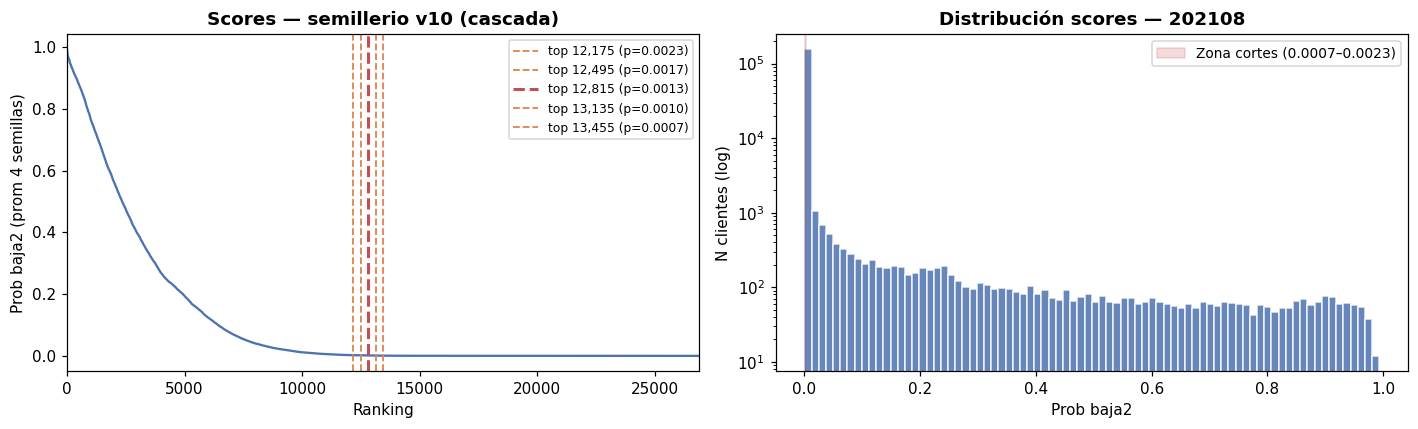

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions6
  ✓ v10cascada_sem42_top12175_1009_1611.csv
  ✓ v10cascada_sem42_top12495_1009_1611.csv
  ✓ v10cascada_sem42_top12815_1009_1611.csv
  ✓ v10cascada_sem42_top13135_1009_1611.csv
  ✓ v10cascada_sem42_top13455_1009_1611.csv
  ✓ v10cascada_sem123_top12175_1009_1611.csv
  ✓ v10cascada_sem123_top12495_1009_1611.csv
  ✓ v10cascada_sem123_top12815_1009_1611.csv
  ✓ v10cascada_sem123_top13135_1009_1611.csv
  ✓ v10cascada_sem123_top13455_1009_1611.csv
  ✓ v10cascada_sem777_top12175_1009_1611.csv
  ✓ v10cascada_sem777_top12495_1009_1611.csv
  ✓ v10cascada_sem777_top12815_1009_1611.csv
  ✓ v10cascada_sem777_top13135_1009_1611.csv
  ✓ v10cascada_sem777_top13455_1009_1611.csv
  ✓ v10cascada_sem2024_top12175_1009_1611.csv
  ✓ v10cascada_sem2024_top12495_1009_1611.csv
  ✓ v10cascada_sem2024_top12815_1009_1611.csv
  ✓ v10cascada_sem2024_top13135_1009_1611.csv
  ✓ v10cascada_sem2024_top13455_1009_1611.

In [19]:
if not MEJORÓ and not FORZAR_SUBMIT:
    print('Submission cancelada.')
else:
    prob_prom     = np.mean(probs_semillerio, axis=0)
    scores_sorted = np.sort(prob_prom)[::-1]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    ax = axes[0]
    ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted, color='#4C72B0', lw=1.5)
    for n in CORTES_N:
        t     = float(scores_sorted[min(n-1, len(scores_sorted)-1)])
        color = '#C44E52' if n == N_OPT else '#DD8452'
        lw    = 2.0 if n == N_OPT else 1.2
        ax.axvline(n, color=color, ls='--', lw=lw, label=f'top {n:,} (p={t:.4f})')
    ax.set_xlim(0, max(CORTES_N) * 2)
    ax.set_title('Scores — semillerio v10 (cascada)', fontweight='bold')
    ax.set_xlabel('Ranking'); ax.set_ylabel('Prob baja2 (prom 4 semillas)')
    ax.legend(fontsize=8)

    ax = axes[1]
    ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
    ax.set_yscale('log')
    umbral_min = float(scores_sorted[max(CORTES_N)-1])
    umbral_max = float(scores_sorted[min(CORTES_N)-1])
    ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
               label=f'Zona cortes ({umbral_min:.4f}–{umbral_max:.4f})')
    ax.set_title('Distribución scores — 202108', fontweight='bold')
    ax.set_xlabel('Prob baja2'); ax.set_ylabel('N clientes (log)')
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

    # Generación de archivos
    archivos = []
    print(f'Generando archivos en: {RUTA_SUBS}')
    for i_s, semilla in enumerate(SEMILLAS):
        prob_s = probs_semillerio[i_s]
        for n_corte in CORTES_N:
            ranking  = np.argsort(prob_s)[::-1][:n_corte]
            ids_int  = ids_pred[ranking].astype(int)
            nombre   = f'v10cascada_sem{semilla}_top{n_corte}_{TS}'
            ruta     = RUTA_SUBS / f'{nombre}.csv'
            pd.Series(ids_int).to_csv(ruta, index=False, header=False)
            archivos.append({'nombre': nombre, 'semilla': semilla,
                             'n_corte': n_corte, 'n_clientes': len(ids_int)})
            print(f'  ✓ {nombre}.csv')

    pd.DataFrame(archivos).to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)

    ruta_v  = RUTA_SUBS / f'{archivos[0]["nombre"]}.csv'
    df_v    = pd.read_csv(ruta_v, header=None)
    tiene_e = df_v[0].astype(str).str.lower().str.contains('e').any()
    print(f'\nVerificación: sin notación científica: {"✓" if not tiene_e else "✗ PROBLEMA"}')
    print(f'Total archivos: {len(archivos)}')

    nombre_submit = f'v10_cascada_{TS}'
    print('\n' + '='*60)
    print('SUBMIT EN ZULIP')
    print('='*60)
    print(f'Cuerpo: submit {nombre_submit}')
    print(f'Adjuntos: {len(archivos)} archivos .csv de submissions6/')
    print(f'(no incluir log_{TS}.csv)')
    print()
    print(f'Ganancia walk-forward fold_4: ${g_v10_f4:,.0f}')
    print(f'vs v5:                        {signo}${delta/1e6:.1f}M')
    print(f'Centro N: {N_OPT:,} | Cortes: {CORTES_N}')
    print(f'Submit público anterior: 87.07M')

    del df; gc.collect()
    print('\n✓ Notebook 10 completada.')